### TASK 4: TASK PREDICTION ANALYSIS


--- Historical Annual Releases (2000 onwards) ---
    release_year  title_count
12          2012          236
13          2013          286
14          2014          352
15          2015          555
16          2016          901
17          2017         1030
18          2018         1146
19          2019         1030
20          2020          953
21          2021          592


c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


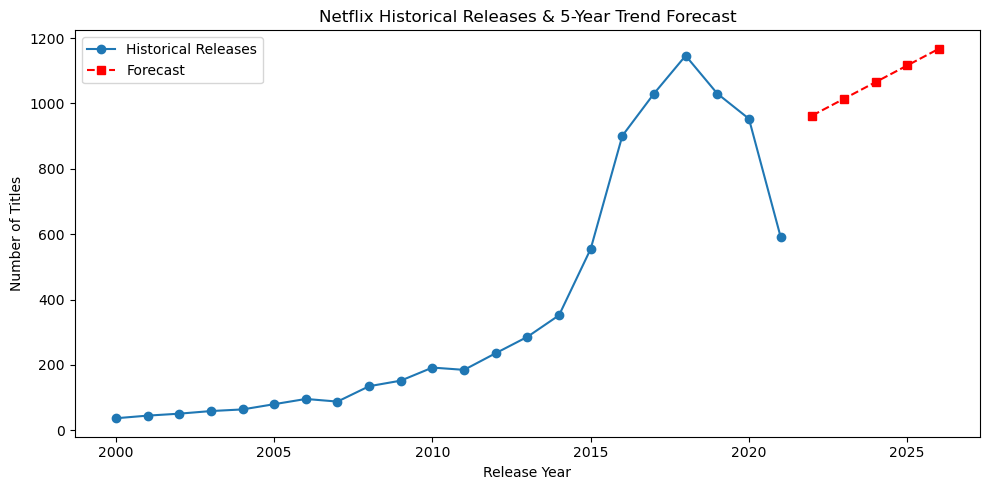


--- Forecasted Growth ---
   release_year  predicted_title_count
0          2022                  963.0
1          2023                 1014.0
2          2024                 1065.0
3          2025                 1116.0
4          2026                 1167.0

Model Slope (Annual Growth Rate): 51.06 titles/year


In [2]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
data_dir = project_root / 'data'
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Load cleaned dataset
df = pd.read_csv(data_dir / 'cleaned_netflix_data.csv')

# Step 1: Prepare release-year data
yearly_counts = df[df['release_year'] >= 2000]['release_year'].value_counts().sort_index().reset_index()
yearly_counts.columns = ['release_year', 'title_count']

# Step 2: Analyze yearly content trends
print("\n--- Historical Annual Releases (2000 onwards) ---")
print(yearly_counts.tail(10))

# Step 3: Build forecasting models
X = yearly_counts[['release_year']]
y = yearly_counts['title_count']

model = LinearRegression()
model.fit(X, y)

# Forecast next 5 years
last_year = yearly_counts['release_year'].max()
future_years = np.array(range(last_year + 1, last_year + 6)).reshape(-1, 1)
future_preds = model.predict(future_years)

forecast_df = pd.DataFrame({
    'release_year': future_years.flatten(),
    'predicted_title_count': np.round(future_preds, 0)
})

# Step 4: Visualize future predictions
plt.figure(figsize=(10, 5))
plt.plot(yearly_counts['release_year'], yearly_counts['title_count'], marker='o', label='Historical Releases')
plt.plot(forecast_df['release_year'], forecast_df['predicted_title_count'], marker='s', linestyle='--', color='red', label='Forecast')
plt.title("Netflix Historical Releases & 5-Year Trend Forecast")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.tight_layout()
plt.show()

# Step 5: Interpret results
print("\n--- Forecasted Growth ---")
print(forecast_df)
print(f"\nModel Slope (Annual Growth Rate): {model.coef_[0]:.2f} titles/year")